In [1]:
import pandas as pd
df = pd.read_csv("dataset.csv")

In [2]:
print(df.head())


   id                                               text          intent  \
0   1  Plan a 2-day trip to Nuwara Eliya for a family...  plan_itinerary   
1   2  Create a 3-day itinerary covering Kandy and Si...  plan_itinerary   
2   3  Create a 7-day itinerary covering Mirissa and ...  plan_itinerary   
3   4  I need a 4-day eco friendly itinerary in Nuwar...  plan_itinerary   
4   5  Create a 7-day itinerary covering Ella and Kan...  plan_itinerary   

   split  
0  train  
1  train  
2  train  
3  train  
4  train  


In [3]:
print(df.shape)

(2200, 4)


In [4]:
print("\n=== Columns ===")
print(df.columns)

print("\n=== Intent distribution ===")
print(df['intent'].value_counts())

print("\n=== Split distribution ===")
print(df['split'].value_counts())

print("\n=== Sample examples ===")
print(df.sample(5))


=== Columns ===
Index(['id', 'text', 'intent', 'split'], dtype='object')

=== Intent distribution ===
intent
plan_itinerary         200
recommend_pois         200
modify_itinerary       200
crowd_forecast         200
info_attraction        200
info_accommodation     200
info_transport         200
info_visa_policy       200
update_preferences     200
explanation_request    200
generic_fact_query     200
Name: count, dtype: int64

=== Split distribution ===
split
train    1760
val       220
test      220
Name: count, dtype: int64

=== Sample examples ===
        id                                               text  \
206    207  Suggest photography places near Mirissa for on...   
1939  1940          Why did you say Sigiriya will be crowded?   
280    281      Suggest quiet places near Colombo for one day   
1171  1172  Suggest strict hotels in Ella for elderly parents   
1301  1302  How long does it take to go from Kandy to Trin...   

                   intent  split  
206        rec

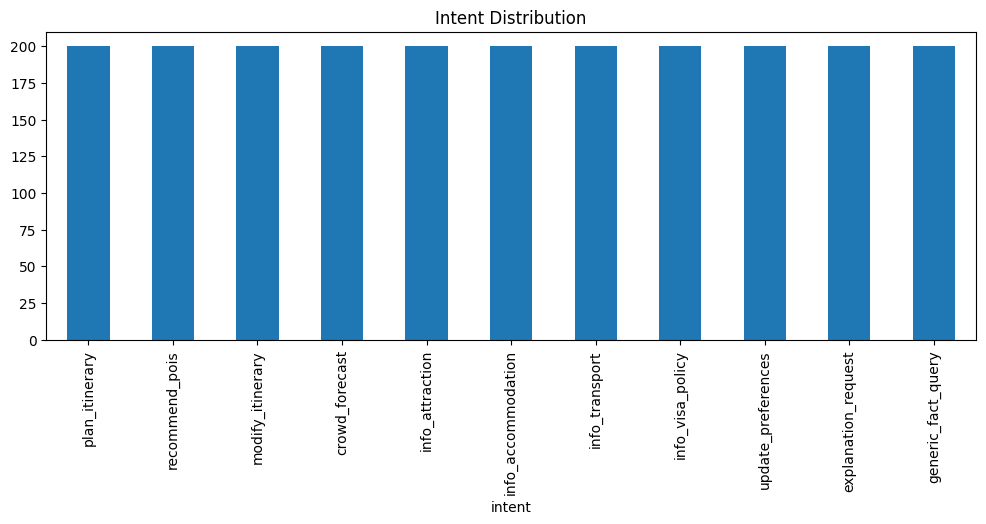

In [5]:
import matplotlib.pyplot as plt

df['intent'].value_counts().plot(kind='bar', figsize=(12,4))
plt.title("Intent Distribution")
plt.show()


In [6]:
dup_texts = df['text'][df['text'].duplicated()].unique()



In [7]:
df_duplicates = df[df['text'].isin(dup_texts)]
df_duplicates


,id,text,intent,split
3,4,I need a 4-day eco friendly itinerary in Nuwar...,plan_itinerary,train
11,12,I need a 6-day eco friendly itinerary in Galle...,plan_itinerary,train
12,13,I need a 5-day eco friendly itinerary in Kandy...,plan_itinerary,train
14,15,I need a 5-day eco friendly itinerary in Colom...,plan_itinerary,train
27,28,I need a 3-day eco friendly itinerary in Nuwar...,plan_itinerary,train
...,...,...,...,...
2193,2194,How is the weather in Galle in August?,generic_fact_query,test
2195,2196,What local customs should I know in Sri Lanka?,generic_fact_query,test
2196,2197,"Kandy august wala weather kohomada, honda da y...",generic_fact_query,test
2198,2199,"Kandy august wala weather kohomada, honda da y...",generic_fact_query,test


In [8]:
print("Before:", len(df))

df_no_exact_dups = df.drop_duplicates(subset=['text', 'intent']).reset_index(drop=True)

print("After :", len(df_no_exact_dups))
print("Removed exact duplicates:", len(df) - len(df_no_exact_dups))


Before: 2200
After : 801
Removed exact duplicates: 1399


In [9]:
# Count how many rows per intent after removing exact duplicates
intent_counts = df_no_exact_dups['intent'].value_counts().reset_index()

intent_counts.columns = ['intent', 'count']
print(intent_counts)


                 intent  count
0        plan_itinerary    168
1        recommend_pois    146
2        info_transport    137
3        crowd_forecast    106
4    info_accommodation     68
5       info_attraction     52
6    generic_fact_query     41
7   explanation_request     33
8      modify_itinerary     18
9    update_preferences     18
10     info_visa_policy     14


In [10]:
# Count how many rows per intent after removing exact duplicates
intent_counts = df_no_exact_dups['intent'].value_counts().reset_index()

intent_counts.columns = ['intent', 'count']

# Save to CSV
intent_counts.to_csv("Without_duplicates.csv", index=False)

print("Without_duplicates.csv")
print(intent_counts)


Without_duplicates.csv
                 intent  count
0        plan_itinerary    168
1        recommend_pois    146
2        info_transport    137
3        crowd_forecast    106
4    info_accommodation     68
5       info_attraction     52
6    generic_fact_query     41
7   explanation_request     33
8      modify_itinerary     18
9    update_preferences     18
10     info_visa_policy     14


In [11]:
# After running:
# df_no_exact_dups = df.drop_duplicates(subset=['text', 'intent']).reset_index(drop=True)

# Save cleaned dataset to CSV
df_no_exact_dups.to_csv("dataset_no_dups.csv", index=False)

print("dataset_no_dups.csv")


dataset_no_dups.csv


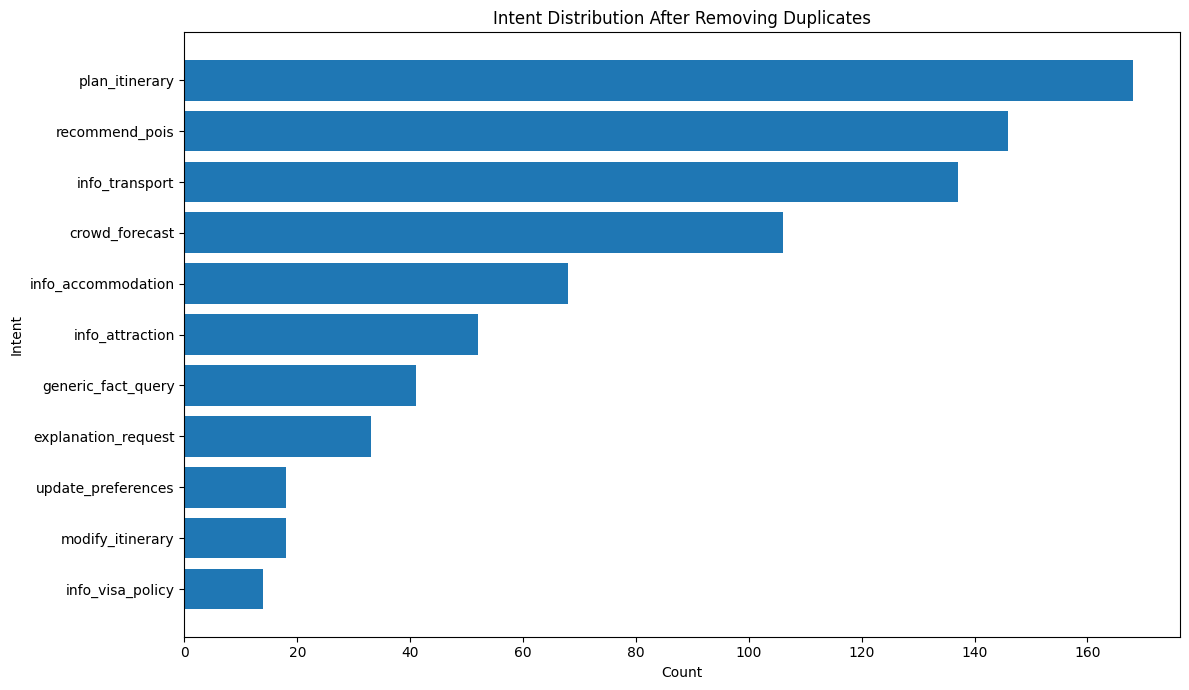

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load full dataset (after removing duplicates)
df = pd.read_csv("dataset_no_dups.csv")

# Step 1: Compute counts per intent
intent_counts = df['intent'].value_counts().reset_index()
intent_counts.columns = ['intent', 'count']

# Step 2: Sort by count (optional, recommended)
intent_counts = intent_counts.sort_values("count", ascending=True)

# Step 3: Plot
plt.figure(figsize=(12, 7))
plt.barh(intent_counts["intent"], intent_counts["count"])
plt.xlabel("Count")
plt.ylabel("Intent")
plt.title("Intent Distribution After Removing Duplicates")
plt.tight_layout()
plt.show()



In [13]:
df[df.duplicated('text', keep=False)]


,id,text,intent,split


In [14]:
import pandas as pd

df = pd.read_csv("datasetV1.csv")
len(df)



871

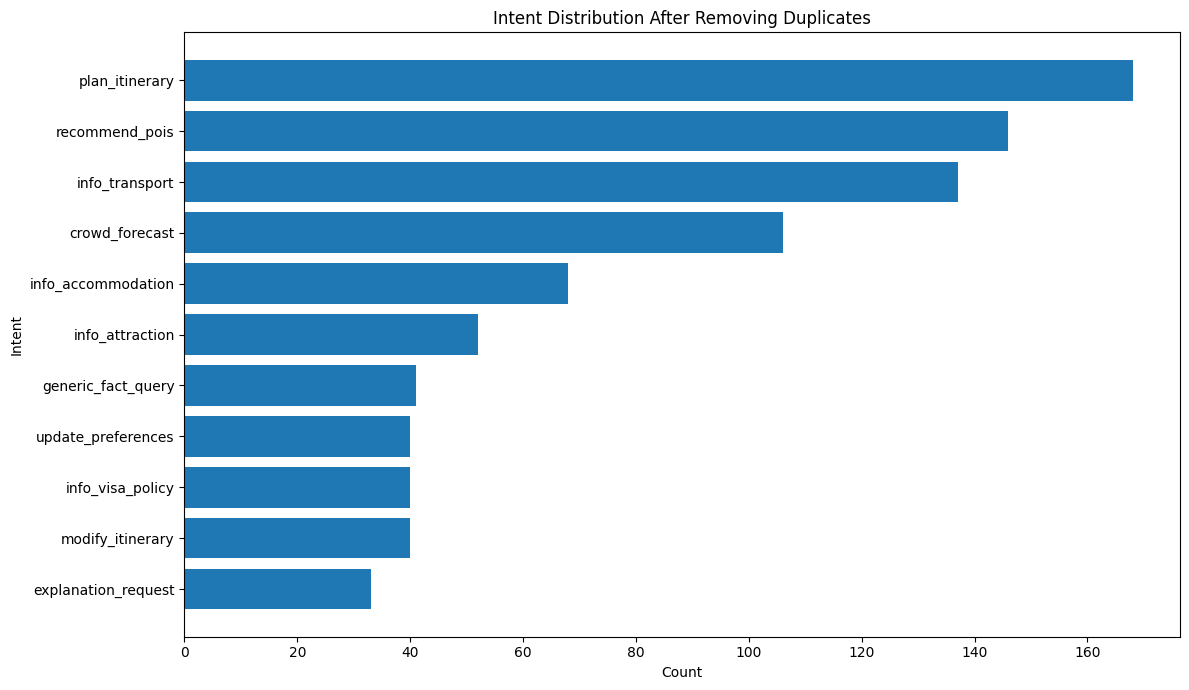

In [15]:
# Step 1: Compute counts per intent
intent_counts = df['intent'].value_counts().reset_index()
intent_counts.columns = ['intent', 'count']

# Step 2: Sort by count (optional, recommended)
intent_counts = intent_counts.sort_values("count", ascending=True)

# Step 3: Plot
plt.figure(figsize=(12, 7))
plt.barh(intent_counts["intent"], intent_counts["count"])
plt.xlabel("Count")
plt.ylabel("Intent")
plt.title("Intent Distribution After Removing Duplicates")
plt.tight_layout()
plt.show()

In [16]:
df = pd.read_csv("datasetV1.csv")

# Count rows per intent
intent_counts = df['intent'].value_counts()

print(intent_counts)

intent
plan_itinerary         168
recommend_pois         146
info_transport         137
crowd_forecast         106
info_accommodation      68
info_attraction         52
generic_fact_query      41
modify_itinerary        40
info_visa_policy        40
update_preferences      40
explanation_request     33
Name: count, dtype: int64


In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib


In [18]:
# 1. Load dataset
df = pd.read_csv("datasetV1.csv")

# Keep only the columns we need
df = df[['text', 'intent']].dropna()

print("Total samples:", len(df))
print(df['intent'].value_counts())

Total samples: 871
intent
plan_itinerary         168
recommend_pois         146
info_transport         137
crowd_forecast         106
info_accommodation      68
info_attraction         52
generic_fact_query      41
modify_itinerary        40
info_visa_policy        40
update_preferences      40
explanation_request     33
Name: count, dtype: int64


In [21]:

# 2. Train / validation / test split (stratified by intent)
X = df['text'].astype(str)
y = df['intent']

# First split: train vs temp (val+test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.2,            # 80% train, 20% temp
    stratify=y,
    random_state=42
)

# Second split: val vs test (10%/10% of total)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,            # split temp into 50% val, 50% test
    stratify=y_temp,
    random_state=42
)

print("Train size:", len(X_train))
print("Val size:  ", len(X_val))
print("Test size: ", len(X_test))

Train size: 696
Val size:   87
Test size:  88


In [22]:
# 3. TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    max_features=20000,       # cap vocabulary size
    ngram_range=(1, 2),       # unigrams + bigrams
    lowercase=True
)

# Fit on training text only, then transform all splits
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec   = vectorizer.transform(X_val)
X_test_vec  = vectorizer.transform(X_test)

print("TF-IDF matrix shape (train):", X_train_vec.shape)

TF-IDF matrix shape (train): (696, 1277)


In [23]:
# 4. Logistic Regression classifier
clf = LogisticRegression(
    max_iter=1000,
    n_jobs=-1,                # use all CPU cores
    class_weight="balanced",  # help with class imbalance
    solver="lbfgs",           # good default
    multi_class="auto"
)

# Train
clf.fit(X_train_vec, y_train)

/Users/dev/Desktop/Tourism_MAS/venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'auto'


In [24]:
# 5. Evaluation on validation set (you can tune here if needed)
y_val_pred = clf.predict(X_val_vec)
print("\n=== Validation Performance ===")
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))


=== Validation Performance ===
Accuracy: 0.9885057471264368
                     precision    recall  f1-score   support

     crowd_forecast       1.00      1.00      1.00        10
explanation_request       1.00      0.75      0.86         4
 generic_fact_query       1.00      1.00      1.00         4
 info_accommodation       1.00      1.00      1.00         7
    info_attraction       1.00      1.00      1.00         5
     info_transport       1.00      1.00      1.00        14
   info_visa_policy       1.00      1.00      1.00         4
   modify_itinerary       0.80      1.00      0.89         4
     plan_itinerary       1.00      1.00      1.00        17
     recommend_pois       1.00      1.00      1.00        14
 update_preferences       1.00      1.00      1.00         4

           accuracy                           0.99        87
          macro avg       0.98      0.98      0.98        87
       weighted avg       0.99      0.99      0.99        87



In [25]:
# 6. Final evaluation on test set
y_test_pred = clf.predict(X_test_vec)
print("\n=== Test Performance ===")
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))

print("\nConfusion matrix (test):")
print(confusion_matrix(y_test, y_test_pred))

# 7. Save the vectorizer + model for later use
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")
joblib.dump(clf, "logreg_intent_classifier.joblib")
print("\nSaved model and vectorizer to disk.")


=== Test Performance ===
Accuracy: 0.9886363636363636
                     precision    recall  f1-score   support

     crowd_forecast       1.00      1.00      1.00        11
explanation_request       1.00      1.00      1.00         3
 generic_fact_query       1.00      1.00      1.00         4
 info_accommodation       1.00      0.86      0.92         7
    info_attraction       1.00      1.00      1.00         5
     info_transport       1.00      1.00      1.00        14
   info_visa_policy       1.00      1.00      1.00         4
   modify_itinerary       0.80      1.00      0.89         4
     plan_itinerary       1.00      1.00      1.00        17
     recommend_pois       1.00      1.00      1.00        15
 update_preferences       1.00      1.00      1.00         4

           accuracy                           0.99        88
          macro avg       0.98      0.99      0.98        88
       weighted avg       0.99      0.99      0.99        88


Confusion matrix (test):
[